# DuckDB Masterclass — Capítulo 11
## Analytics Engineering: SQL em camadas e dbt-duckdb

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 11.1 — Objetivos e diagnóstico

- Distinguir camada staging de mart.
- Construir transformações SQL e validar qualidade.
- Gerar um projeto dbt mínimo sem exigir ferramenta instalada.
- Opcionalmente executar `dbt` quando o ambiente já estiver configurado.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 11.2 — Conceitos essenciais

O dbt estrutura dependências, materializações, testes e documentação em um projeto. Executar SQL manualmente no DuckDB **não é** o mesmo que executar dbt. Por isso, o capítulo separa simulação de camadas e projeto dbt real opcional.

### 🗺️ Modelo visual — Analytics Engineering: SQL em camadas e dbt-duckdb

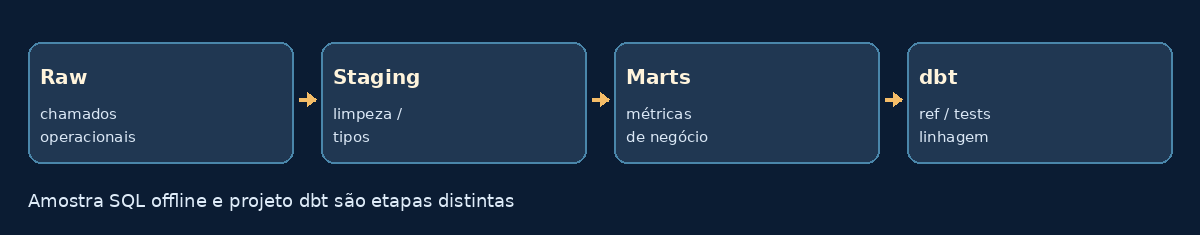

*Ilustração esquemática; não representa medição experimental.*

## 11.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 11.4 — 🔬 Simular staging e mart diretamente em SQL

**Hipótese / tarefa:** Normalizar status de chamados e calcular agregados.

In [ ]:
import duckdb
from IPython.display import display
con = duckdb.connect(':memory:')
print('DuckDB:', duckdb.__version__)
con.execute("""CREATE TABLE raw_chamados AS SELECT * FROM (VALUES
(1,' FECHADO ',10),(2,'ABERTO',12),(3,' FECHADO ',8)
) t(chamado_id,status,duracao_h)""")
con.execute('CREATE VIEW stg_chamados AS SELECT chamado_id,UPPER(TRIM(status)) status,duracao_h FROM raw_chamados')
con.execute('CREATE TABLE mart_status AS SELECT status,COUNT(*) chamados,AVG(duracao_h) duracao_media FROM stg_chamados GROUP BY status')
display(con.execute('SELECT * FROM mart_status ORDER BY status').df())

**Interpretação e limite:** Exemplo SQL estabelece apenas a lógica do modelo.

## 11.5 — 🔬 Testar unicidade e valores aceitos

**Hipótese / tarefa:** Impedir duplicatas e statuses inválidos na base.

In [ ]:
assert con.execute('SELECT COUNT(*)=COUNT(DISTINCT chamado_id) FROM stg_chamados').fetchone()[0]
invalidos=con.execute("SELECT COUNT(*) FROM stg_chamados WHERE status NOT IN ('ABERTO','FECHADO') OR status IS NULL").fetchone()[0]
assert invalidos==0
print('Testes SQL de exemplo aprovados; ainda não executamos dbt.')

**Interpretação e limite:** Testes SQL não substituem `dbt test`.

## 11.6 — 🔬 Gerar mini projeto dbt-duckdb

**Hipótese / tarefa:** Criar arquivos locais de configuração, staging e mart.

In [ ]:
from pathlib import Path
import tempfile,textwrap
tmp_dbt=tempfile.TemporaryDirectory()
projeto=Path(tmp_dbt.name)/'telco_dbt'
(projeto/'models').mkdir(parents=True,exist_ok=True)
(projeto/'dbt_project.yml').write_text('name: telco_dbt\nversion: 1.0.0\nconfig-version: 2\nprofile: telco_dbt\nmodel-paths: [models]\n',encoding='utf-8')
(projeto/'models'/'stg_chamados.sql').write_text("select 1 as chamado_id, 'FECHADO' as status union all select 2, 'ABERTO'",encoding='utf-8')
(projeto/'models'/'mart_status.sql').write_text("select status, count(*) as chamados from {{ ref('stg_chamados') }} group by status",encoding='utf-8')
(projeto/'models'/'schema.yml').write_text('version: 2\nmodels:\n  - name: stg_chamados\n    columns:\n      - name: chamado_id\n        data_tests: [unique, not_null]\n',encoding='utf-8')
print('Projeto mínimo gerado:',[p.name for p in sorted((projeto/'models').iterdir())])

**Interpretação e limite:** Arquivos gerados ficam em pasta temporária, não expõem credenciais.

## 11.7 — 🔬 Execução opcional e explícita do dbt

**Hipótese / tarefa:** Explicar comandos e verificar ferramenta, sem disparar instalação.

In [ ]:
import importlib.util
existe_dbt=importlib.util.find_spec('dbt') is not None
print('dbt instalado no kernel:',existe_dbt)
print('Para executar: configure profiles.yml com adapter duckdb e rode dbt debug, dbt run, dbt test.')
print('Nenhum comando externo foi executado automaticamente.')

**Interpretação e limite:** Sem `dbt-duckdb`, o projeto fica como exemplo reproduzível para instalação posterior.

## 11.8 — 🎯 Desafio profissional

Explique diferenças entre teste de SQL isolado e teste dbt ligado ao DAG de modelos.

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

O arquivo `profiles.yml` e conexão devem ser configurados antes de executar o CLI; `ref()` define dependências do dbt.

## 11.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 11.10 — Referências, reprodução e publicação

- [dbt-duckdb adapter](https://github.com/duckdb/dbt-duckdb)
- [DuckDB + dbt](https://duckdb.org/docs/stable/guides/python/dbt)
- [dbt Models](https://docs.getdbt.com/docs/build/sql-models)

**Notas de engenharia:** Projeto é gerado, mas `dbt run/test` exige ambiente compatível; execução opcional não foi validada.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.